In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('../data/telco_churn.csv')
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
# Try converting to numbers; anything that can't convert becomes NaN (missing)
total = pd.to_numeric(df['TotalCharges'], errors='coerce')

print("Rows that failed to convert:", total.isna().sum())
df[total.isna()][["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Rows that failed to convert: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


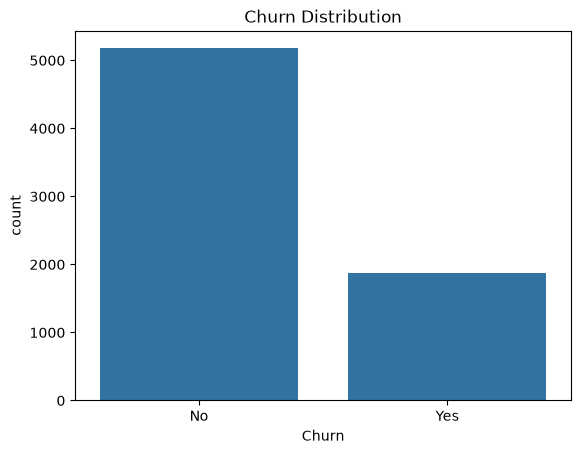

In [6]:
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True).round(3))

sns.countplot(data=df, x="Churn")
plt.title("Churn Distribution")
plt.show()

Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: ChurnFlag, dtype: float64


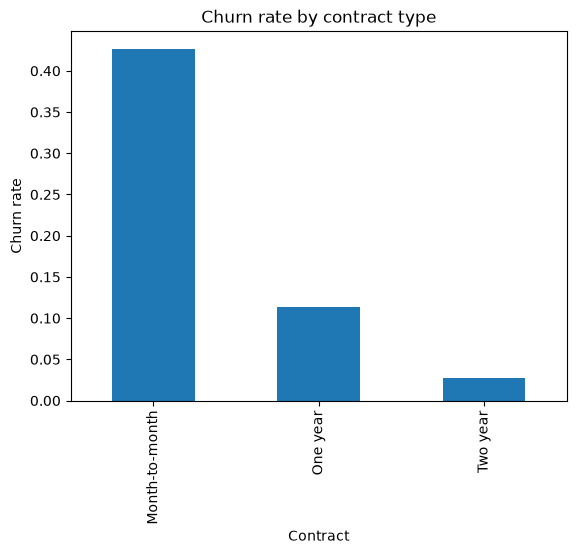

In [7]:
churn_by_contract = (
    df.assign(ChurnFlag=(df["Churn"] == "Yes").astype(int))
      .groupby("Contract")["ChurnFlag"]
      .mean()
      .round(3)
)
print(churn_by_contract)
churn_by_contract.plot(kind="bar", title="Churn rate by contract type")
plt.ylabel("Churn rate")
plt.show()

In [8]:
print(df.loc[488, "TotalCharges"] == " ")
print(repr(df.loc[488, "TotalCharges"]))

True
' '


       tenure  MonthlyCharges
Churn                        
No       37.6            61.3
Yes      18.0            74.4


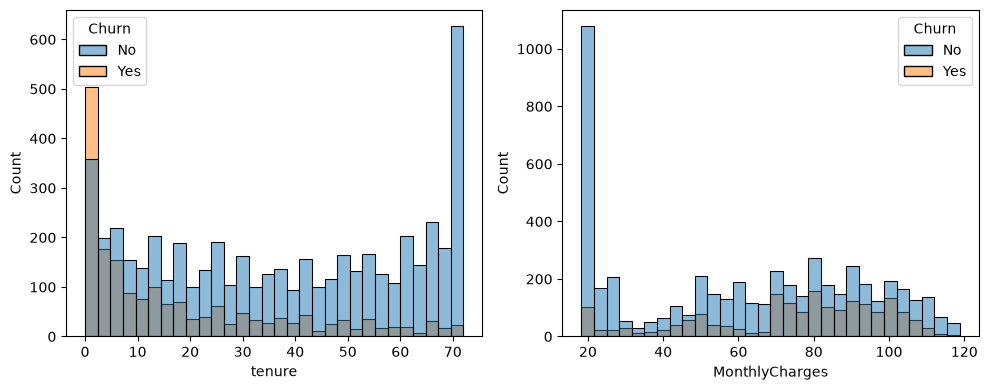

In [9]:
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

print(df.groupby("Churn")[["tenure", "MonthlyCharges"]].mean().round(1))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, ax=axes[0])
sns.histplot(data=df, x="MonthlyCharges", hue="Churn", bins=30, ax=axes[1])
plt.tight_layout()
plt.show()